In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

In [41]:
data = pd.read_csv(r"X:\pricte\Customer_Churn _dataset\DataCoSupplyChainDataset.csv", encoding ="Latin-1")
data.head(5)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
data.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

## Exploratory Data Analysis (EDA)

In [6]:
# Check the row and cols
print('row, cols:', data.shape)

# check the columns in data nest linne
print('\n columns:')
print(data.columns.tolist())

# check duplicates 
print("\n Num Duplicates:", data.duplicated().sum())


# Messing values 
print("\n Missing Values(Top 20):", data.isna().sum().sort_values(ascending=False).head(10))

row, cols: (180519, 53)

 columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [7]:
(data['Benefit per order'] == data['Order Profit Per Order']).value_counts()


True    180519
Name: count, dtype: int64

In [8]:
# Data Cleanig 
columns_to_drop =[
    'Benefit per order', 'Sales per customer', 'Order Zipcode','Product Description',
    'Category Id','Customer City', 'Customer Country', 'Customer Email', 'Customer Fname',
    'Customer Id', 'Customer Lname', 'Customer Password', 'Customer State', 'Customer Street', 'Customer Zipcode', 
    'Department Id', 'Latitude', 'Longitude',  'Market', 'Order City', 'Order Country', 'Order Customer Id',
     'Order Id', 'Order Item Cardprod Id']

# removing cancel orders since they are not relevant for delivery time analysis and may have different pattans than completes order
data  = data[data['Delivery Status'] != "Shipping canceled"]

# Standaed data conversion
for c in ["order date (DateOrders)", "shipping date (DateOrders)"]:
    data[c] = pd.to_datetime(data[c], errors='coerce', dayfirst=False)

# dropping colimns that are either fully missing, redundant, or have only one value (are thus on varianvce)
data = data.drop(columns=columns_to_drop, errors='ignore')

# after data cleaning, let's check the overview again to see how the dataset change
print('rows,cols:', data.shape)
print('\nMissing values (top5):')
print(data.isna().sum().sort_values(ascending = False).head(5))

rows,cols: (172765, 29)

Missing values (top5):
Type                          0
Sales                         0
shipping date (DateOrders)    0
Product Status                0
Product Price                 0
dtype: int64


In [9]:
# values counts  for categorical columns with low cardinality

for col in data.columns:
    if data[col].nunique() < 10:
        print(f"\n{col}.values counts:")
        print(data[col].value_counts())


Type.values counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real).values counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled).values counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status.values counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk.values counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Segment.values counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Order Item Quantity.values counts:
Order Item Quantity
1    94904
5    19510
4    19481
3    19473
2    19397
Name: count, dtype: int64

Order Status.values counts

In [10]:
# Calculatating the order processing time to delay
data["Order Processing Time"] = (data['shipping date (DateOrders)'] - data["order date (DateOrders)"]).dt.days
data["Delay"] = data["Order Processing Time"]- data["Days for shipment (scheduled)"]

data["Is_Delayed"] = data["Delay"] > 0
data['Order_month']= data['order date (DateOrders)'].dt.month
data['Order_day'] = data ['order date (DateOrders)'].dt.day_name()
data['Order_hour'] = data['order date (DateOrders)'].dt.hour

data.describe()

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,order date (DateOrders),Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,...,Order Profit Per Order,Product Card Id,Product Category Id,Product Price,Product Status,shipping date (DateOrders),Order Processing Time,Delay,Order_month,Order_hour
count,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,...,172765.000000,172765.000000,172765.000000,172765.000000,172765.0,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,0.572900,2016-06-12 15:25:39.457991936,20.662798,0.101625,90243.246097,141.278595,0.120801,2.127694,...,22.032360,692.618858,31.856065,141.278595,0.0,2016-06-16 03:25:14.452927488,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,0.000000,2015-01-01 00:00:00,0.000000,0.000000,1.000000,9.990000,-2.750000,1.000000,...,-4274.979980,19.000000,2.000000,9.990000,0.0,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,0.000000,2015-09-21 18:01:00,5.400000,0.040000,45157.000000,50.000000,0.080000,1.000000,...,7.030000,403.000000,18.000000,50.000000,0.0,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,1.000000,2016-06-11 08:11:00,14.000000,0.090000,90227.000000,59.990002,0.270000,1.000000,...,31.520000,627.000000,29.000000,59.990002,0.0,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,1.000000,2017-02-28 21:08:00,29.990000,0.160000,135305.000000,199.990005,0.360000,3.000000,...,64.800003,1004.000000,45.000000,199.990005,0.0,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1.000000,2018-01-31 23:38:00,500.000000,0.250000,180519.000000,1999.989990,0.500000,5.000000,...,911.799988,1363.000000,76.000000,1999.989990,0.0,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,0.494659,NaN,21.818601,0.070429,52088.128122,139.862956,0.466610,1.453663,...,104.355313,336.471170,15.642216,139.862956,0.0,NaN,1.670187,1.494150,3.405593,6.927276


In [11]:
data["Is_Delayed"].value_counts()
    

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [12]:
# Profitability Flag based on order profit per Order

data ['Profitability Flag'] = np.where(data['Order Profit Per Order']> 0 ,"Profit", np.where(data['Order Profit Per Order']<0 ,"Loss", 'Break_even'))
data ['Profitability Flag'].value_counts()

Profitability Flag
Profit        139354
Loss           32295
Break_even      1116
Name: count, dtype: int64

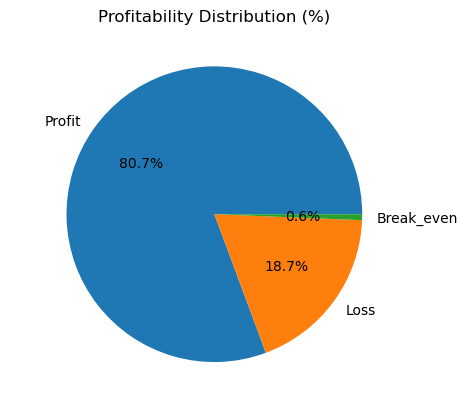

In [13]:
# visualization of profitability distribution
profit_counts = data["Profitability Flag"].value_counts(normalize = True)* 100
profit_counts.plot(kind='pie' , autopct = '%1.1f%%')
plt.ylabel(' ')
plt.title("Profitability Distribution (%)")
plt.show()

In [14]:
# Create the analisis Business KPIs 

In [15]:
def format_func(value):
    if value >= 1e6:
        return f'{value / 1e6:.1f}M $'
    elif values >= le3:
        return f'{value/le3:.1f}K $'
    else:
        return f'(value:.0f) $'

delayed_data = data[data['Delay'] > 0]
metrics ={}
metrics['Total Orders']=len(data)
metrics['Late Deliveries']=len(delayed_data)
metrics['90% Delay (Days)'] = delayed_data['Delay'].quantile(0.90)
metrics['On Time Delivery %']= (1 - float(metrics['Late Deliveries'])/metrics['Total Orders'])*100
metrics['Late Delivery % '] = float(metrics['Late Deliveries']) / metrics['Total Orders']*100
metrics['Total Profit']= format_func(data.loc[data['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total Loss due to delays']= format_func(data.loc[data['Delay'] > 0, 'Order Profit Per Order'].sum())

print('\n------ Business KPIs ------\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")

    else:
        print(f"{k}, {v}")

        


------ Business KPIs ------

Total Orders, 172765
Late Deliveries, 94523
90% Delay (Days): 3.00
On Time Delivery %: 45.29
Late Delivery % : 54.71
Total Profit, 7.5M $
Total Loss due to delays, 2.1M $


## Profitability VS Delivery Time Analysis

In [16]:
profit_metrics = (
    data.groupby('Delay')['Order Profit Per Order']
    .agg(
        mean_profit='mean',
        total_profit = 'sum',
        order_count = 'count'
    )
    .reset_index()
)

profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


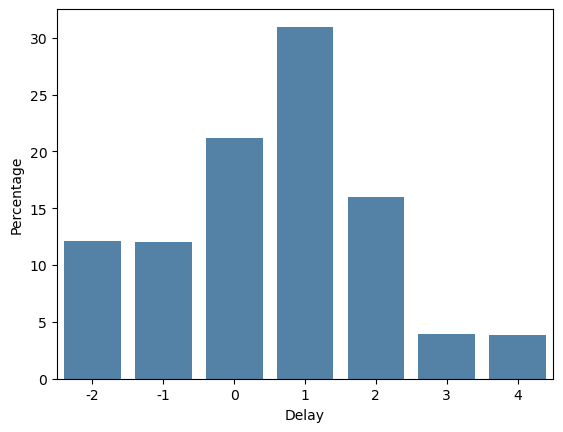

In [17]:
# delay_distribution Repot 

delay_distribution = (
    data['Delay']
        .value_counts(normalize = True)
        .sort_index()*100
).reset_index()

delay_distribution.columns = ['Delay', 'Percentage']
sns.barplot(
    data=delay_distribution,
    x='Delay',
    y='Percentage',
    color='steelblue'
)
plt.show()
# # Rename columns
# delay_distribution.columns = ['Delay', 'Percentage']

# # Create bar chart
# plt.figure(figsize=(10, 5))

# sns.barplot(
#     data=delay_distribution,
#     x='Delay',
#     y='Percentage',
#     color='steelblue'
# )

# plt.title('Delay Distribution')
# plt.xlabel('Delay (Days)')
# plt.ylabel('Percentage of Orders (%)')
# plt.xticks(rotation=45)

# plt.tight_layout()
# plt.show()


 Profit Metrics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.4,487596.1,20873
1,-1,21.6,447629.2,20719
2,0,22.2,815430.2,36650
3,1,22.3,1194894.7,53503
4,2,21.1,582111.0,27551
5,3,20.0,135652.7,6772
6,4,21.4,143106.7,6697



 Delay Distribution (%):


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


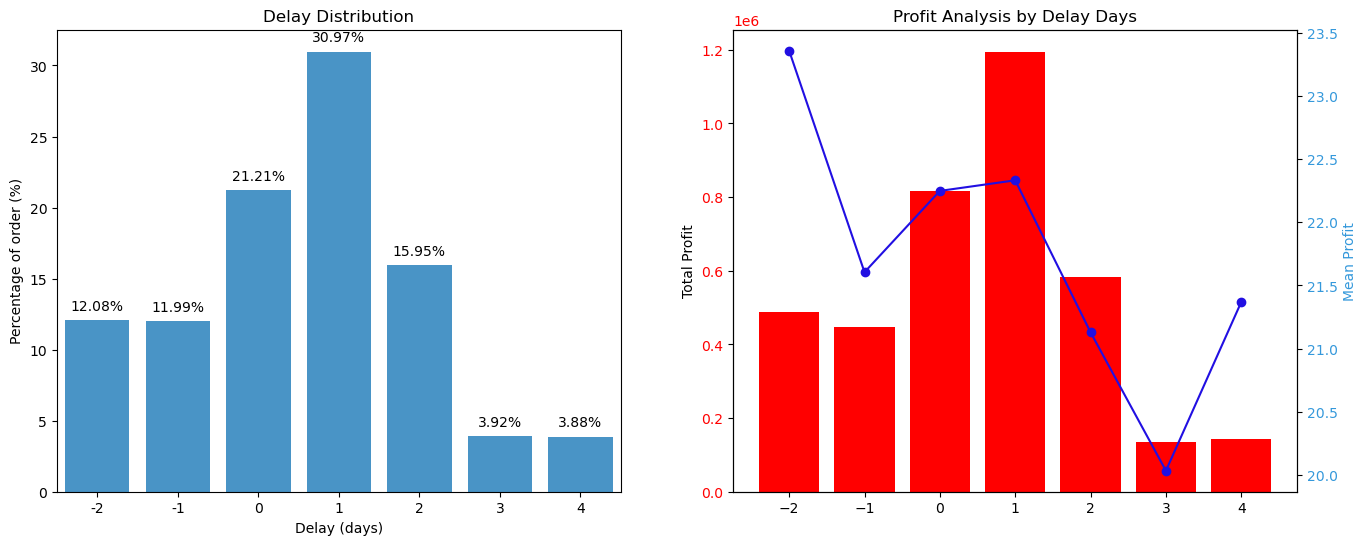

In [18]:
delay_distribution.columns = ['Delay_Days' , 'Percentage']

print("\n Profit Metrics by Delay Day:")
display(profit_metrics.round(1))

print("\n Delay Distribution (%):")
display(delay_distribution)

# Define color
accent_color ='#3498DB'
primary_color = '#FF0000'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# First subplot : Delay Distribution
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color=accent_color, ax=ax1)
ax1.set_title('Delay Distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('Percentage of order (%)')

# percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, height + 0.5,  f'{height:.2f}%', ha='center' ,va='bottom')



# Second subplot: Profit Analysis by Delay Days
ax2.set_ylabel('Total Profit')
ax2.set_title('Profit Analysis by Delay Days')
ax2.bar(profit_metrics["Delay"], profit_metrics['total_profit'],color = primary_color, label='Total Profit')
ax2.tick_params(axis ='y', labelcolor =primary_color)


ax3= ax2.twinx()
ax3.set_xlabel('Delay Days')
ax3.set_ylabel('Mean Profit', color=accent_color)
ax3.plot(profit_metrics["Delay"], profit_metrics['mean_profit'],marker = 'o', color="#210FE2", label='Mean Profit')
ax3.tick_params(axis ='y', labelcolor=accent_color)



In [19]:
# Calculate the delay present % category vs
# def computer_delay_pct_by_category(category):
#     cat_data = data.groupby(category).agg(
#         total_orders = ('Delay', 'count'),
#         late_orders=('Is_Delayed', "sum")
#     ).reset_index()
#     cat_data['delay_pct'] = cat_data['late_orders']/ cat_data['total_orders']*100
#     cat_data = cat_data.sort_values('delay_pct', ascending=False).head(10)
#     return cat_data

# categories = ['Order Region', 'Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']

In [20]:
# computer_delay_pct_by_category('Customer Segment')

# Bottleneck Detection

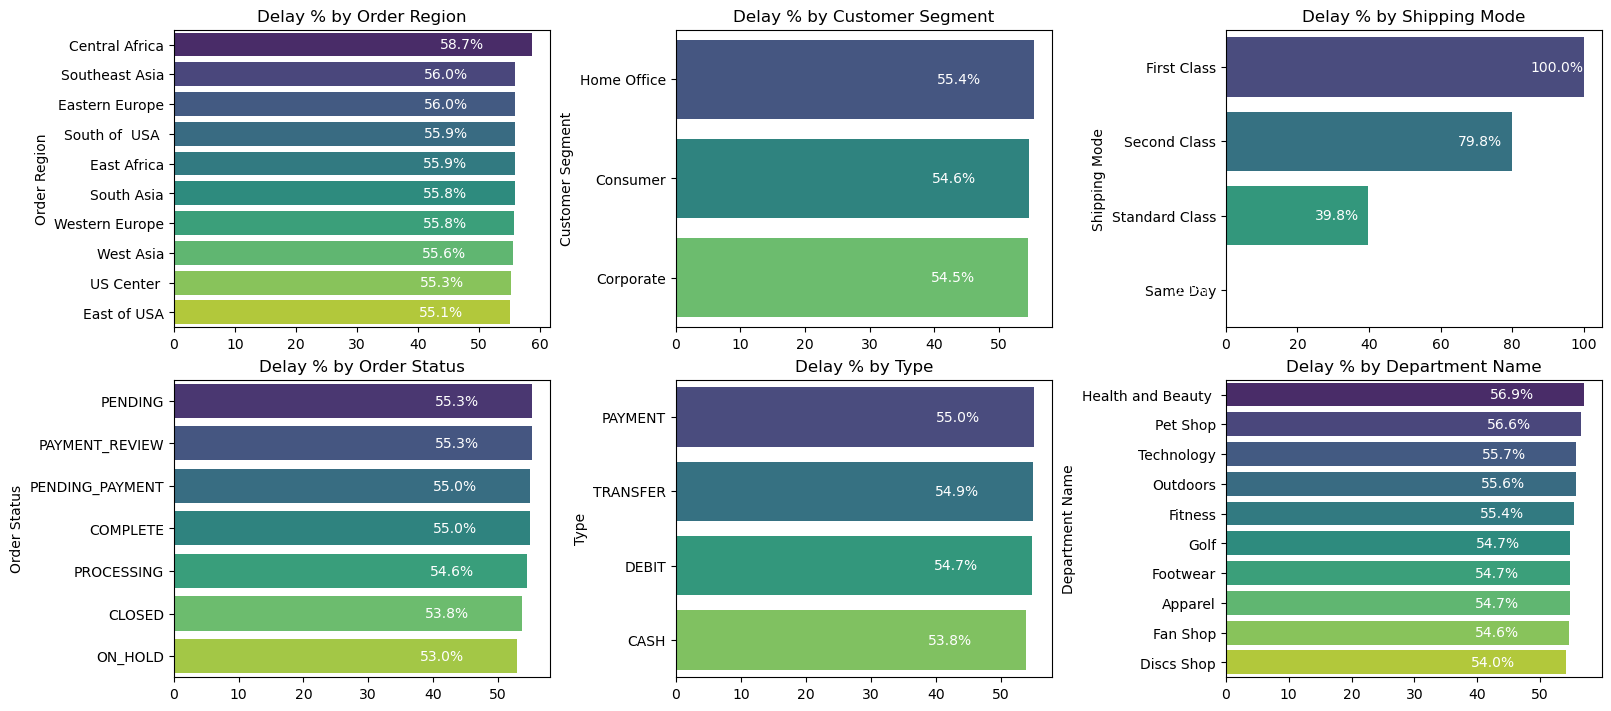

In [21]:
# where is delay  problem check it 

def computer_delay_pct_by_category(category):                               # Calculate the delay present % category vs
    cat_data = data.groupby(category).agg(
        total_orders = ('Delay', 'count'),
        late_orders=('Is_Delayed', "sum")
    ).reset_index()
    cat_data['delay_pct'] = cat_data['late_orders']/ cat_data['total_orders']*100
    cat_data = cat_data.sort_values('delay_pct', ascending=False).head(10)
    return cat_data

categories = ['Order Region', 'Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']

fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
axes = axes.flatten()
    
for ax, category in zip(axes, categories):                                                # Create bar plot
    cat_data = computer_delay_pct_by_category(category)
    sns.barplot(
        data=cat_data,
        x='delay_pct',
        y=category,
        hue=category,
        ax=ax,
        palette='viridis'
    )

    
    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('')
    ax.set_ylabel(category)
    for i, row in cat_data.reset_index().iterrows():
         ax.text(row['delay_pct'] - 15, i,
            f"{row['delay_pct']:.1f}%",
            va='center',
            fontsize=10,
            color='white'
        )
        # ax.test(row['delay_pct'] - 15, i, f"{row['delay_pct']:.1f}%", va='center', fontsize=10, color='white')


plt.show()

# Root Cause Analysis

In [22]:
def top_dirvers_for_region(region):
    data_region = data[data['Order Region']== region].copy()

    drivers = ['Customer Segment', 'Shipping Mode', 'Order Status', 'Type', 'Department Name']

    all_factors=[]
    for factor in drivers:
        temp =(
        data_region.groupby(factor)
        .agg(
            total_orders=("Delay", "count"),
            late_orders=('Is_Delayed', "sum"),
            avg_delay=('Delay', 'mean')
            )
            .reset_index()
        )

    temp['delay_pct']=temp['late_orders'] / temp['total_orders'] * 100
    temp['Driver'] = factor
    temp["Factor_Level"] = factor + ":" + temp[factor].astype(str)

    all_factors.append(temp[['Driver', "Factor_Level", 'delay_pct', 'avg_delay', 'total_orders']])

    # Combine all drivers
    final_data = pd.concat(all_factors)

    # top 10 drivers 
    top_factors = final_data.sort_values('delay_pct', ascending=False).head(10)
    plt.figure()

    # bars =plt.barh(top_factors["Factor_Lavel"], top_factors["delay_pct"])
    bars = plt.barh(
        top_factors["Factor_Level"],
        top_factors['delay_pct']
    )

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel('Driver Factors')
    plt.title(f'Top Drivers of Late Delivery in {region}')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca().invert_yaxis()

    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2,
                f"{width:.1f}%", va='center', fontsize=10, color='white')
    plt.show()
        

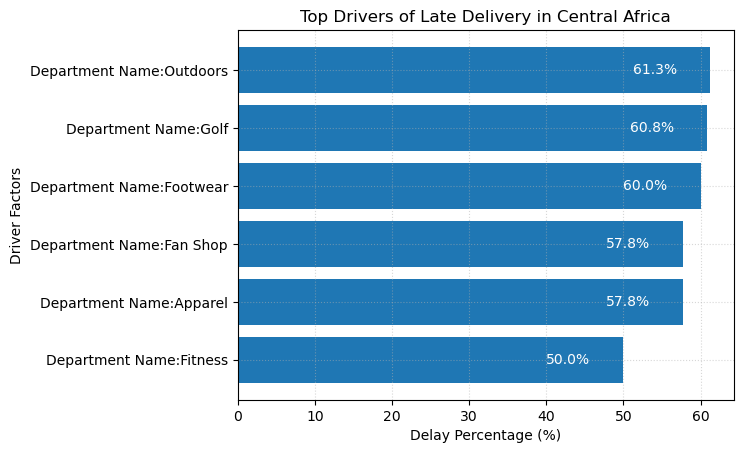

In [23]:
top_dirvers_for_region('Central Africa')

# Time-Based Analysis

In [24]:
# Delay % by Month, Day of week, Hour

delay_by_month = (
    data.groupby('Order_month')['Is_Delayed']
        .mean()
        .reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100


delay_by_day = (
    data.groupby('Order_day')['Is_Delayed']
        .mean()
        .reset_index()
)
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100


delay_by_hour = (
    data.groupby('Order_hour')['Is_Delayed']
        .mean()
        .reset_index()
)
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

In [25]:
delay_by_month

,Order_month,Is_Delayed,delay_pct
0,1,0.542542,54.254150
1,2,0.546046,54.604550
2,3,0.548094,54.809390
3,4,0.545042,54.504230
4,5,0.549980,54.998022
5,6,0.547645,54.764535
6,7,0.537310,53.731048
7,8,0.553871,55.387128
8,9,0.553885,55.388454
9,10,0.540970,54.097044


C:\Users\kumar\AppData\Local\Temp\ipykernel_11160\1304726654.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(delay_by_day['Order_day'], rotation=45)


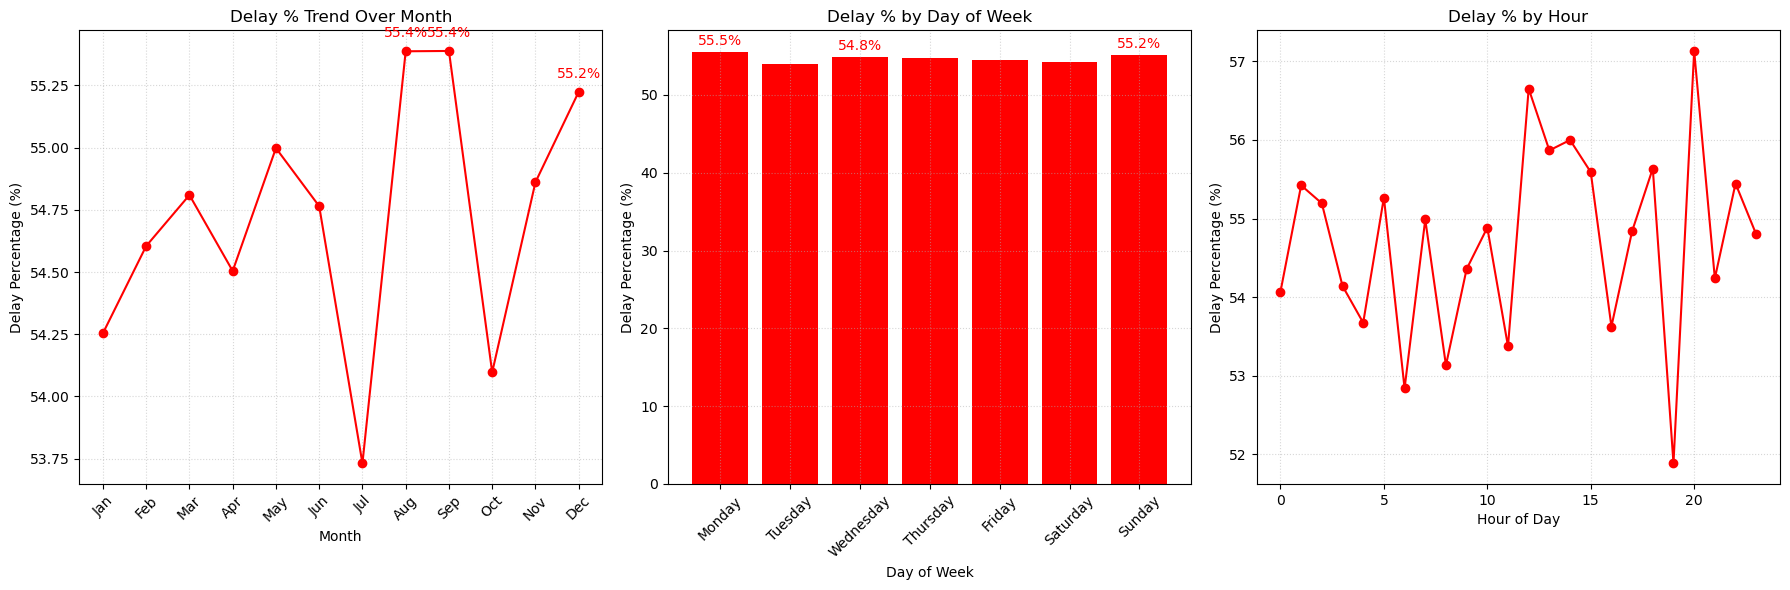

In [26]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Delay % Trend Over Month
ax1.plot(delay_by_month['Order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_xticks(range(1,13))
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")
ax1.grid(True, linestyle=':', alpha=0.5)

danger_color='Red'

# Annotate top 3 highest
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['Order_month'], row['delay_pct']),
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, color=danger_color)



# Subplot 2: Delay % by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['Order_day'] = pd.Categorical(delay_by_day['Order_day'],categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('Order_day')

ax2.bar(delay_by_day['Order_day'],delay_by_day['delay_pct'], color=primary_color)
ax2.set_xticklabels(delay_by_day['Order_day'], rotation=45)
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest bars
top3_day = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_day.iterrows():
    height= row['delay_pct']
    ax2.text(row['Order_day'], height + 0.5, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, color=danger_color)


# Subplot 3: Delay % by Hour
ax3.plot(delay_by_hour['Order_hour'],delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")
ax3.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['Order_hour'], row['delay_pct']),
                textcoords="offset point", xytext=(0, 10), ha='center', fontsize=10, color=danger_color)

plt.tight_layout()
plt.show()


# Machine Learning Modeling

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [28]:
X = data[['Type', 'Days for shipment (scheduled)','Category Name','Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode', 'Order_month', 'Order_hour']]
y = data['Late_delivery_risk']

In [36]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', cat_cols)

# Frequency encoding (low-dimensinal and robust for high-cardinality)
for col in cat_cols:
    freq = X[col].value_counts(normalize=True)
    X[f'{col}_freq'] = X[col].map(freq)

# Keep numeric columns + new encoded features, drop original string categories
X_encoded = X.drop(columns=cat_cols)
print('Shape afte freq+target encoding:', X_encoded.shape)

# use encoded features for modeling
X=X_encoded

# train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


Categorical columns: []
Shape afte freq+target encoding: (172765, 9)


In [37]:
y.value_counts()

Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

In [38]:
# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal=smote.fit_resample(X_train, y_train)

print("After balancing (train):", Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing (train): Counter({0: 79182, 1: 79182})


In [39]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred),2))
    print("Precision:", round(precision_score(y_true, y_pred),2))
    print("Recall:", round(recall_score(y_true, y_pred),2))
    print("\nClassification Report: \n", classification_report(y_true, y_pred),2)
    
    

In [40]:
# Fit the Random Forest model on balanced data

rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rf_balanced = rf_model_balanced.predict(X_test)

evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")



--- Random Forest Classifier ---
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification Report: 
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553
 2
